# 40. Combination Sum II
**Difficulty:** 🟡 Medium · **Topic:** Backtracking · **Pattern:** [Combinations](README.md) · **LeetCode:** https://leetcode.com/problems/combination-sum-ii/

## 💡 Concepts

**Core concept(s):** **Backtracking with sort + skip-duplicates** — the Combination Sum template, with two changes: each element is used at most once, and equal values are never tried twice at the same level.

**Why it applies here:**
- We must list *all* combinations, so we explore a tree of choices (backtracking).
- The input can contain **duplicates** (`[10, 1, 2, 7, 6, 1, 5]` has two `1`s), but the output must not repeat a combination.
- Using the first `1` or the second `1` gives the same combination `[1, 7]`. Generating both and filtering later wastes work.
- After sorting, equal values sit next to each other, so "is this the same value I just tried here?" is one comparison.

**Key intuition:**
- At one level of the tree, every child is "the next number in the combination".
- Two children that start with the same value grow identical subtrees. Keep only the first: `if i > start and c[i] == c[i - 1]: continue`.
- `i > start` (not `i > 0`) still lets the *same value* appear twice in one combination, as `[1, 1, 6]` — via a deeper level, not a sibling.

---

### 📚 What is Recursion?
- A function that calls itself on a smaller version of the same problem, with a **base case** that stops it.
- Waiting calls sit on the **call stack**; the longest chain is the recursion **depth**.
- **Space:** here the depth is at most `n`, because every step moves past at least one element.
- **In Python:** a nested `def backtrack(...)` that reads the outer `candidates` and `res`.

### 📚 What is Backtracking?
- Build the answer in a shared `path`: **choose** (`append`), **explore** (recurse), **un-choose** (`pop`).
- It explores a **tree of choices**; **pruning** skips branches that can't produce a new answer.
- **Complexity:** exponential in the worst case (`2^n` subsets of `n` elements).
- **In Python:** `list` for `path` (`append`/`pop` O(1)), `res.append(path[:])` to save a copy.

### 📚 What is Sorting (for pruning and grouping)?
- `sorted(candidates)` costs `O(n log n)` and does two jobs here.
- **Break:** if `candidates[i] > remain`, every later candidate is too big as well, so stop the loop.
- **Grouping:** equal values become neighbours, so `candidates[i] == candidates[i - 1]` detects a duplicate in O(1).

### 📚 What is a Hash Set? (used by the brute force)
- A `set` stores unique items; it hashes each item to find its slot directly.
- Insert and membership test are **O(1) on average**.
- Lists can't go in a set (they can change), so a combination is stored as a `tuple`.
- **In Python:** `seen = set(); seen.add(tuple(path))`.

---

**Prerequisite knowledge:**
- The Combination Sum template (see [Combination Sum](combination_sum.ipynb)): start index, choose / explore / undo, `break` on a sorted list.

## 📝 Problem

Given a collection of numbers `candidates` (which **may contain duplicates**) and a `target`, return all **unique** combinations whose numbers sum to `target`. Each number may be used **at most once** in a combination. The output must not contain the same combination twice; order does not matter.

**Example 1**
```
candidates = [10, 1, 2, 7, 6, 1, 5], target = 8  ->  [[1, 1, 6], [1, 2, 5], [1, 7], [2, 6]]
```

**Example 2**
```
candidates = [2, 5, 2, 1, 2], target = 5  ->  [[1, 2, 2], [5]]
```

**Constraints:** `1 <= len(candidates) <= 100`, `1 <= candidates[i] <= 50`, `1 <= target <= 30`.

> Three approaches: a brute force that generates every subset and removes duplicates with a set, include/exclude that skips a whole run of equal values, and the start-index loop with sort + skip-duplicate + `i + 1` (the [Combinations](README.md) template).

In [1]:
from typing import List

### Approach 1 — Brute Force: every subset, deduplicate with a set

**Idea:**
1. Sort, so equal combinations come out as identical tuples (`(1, 7)` from either `1`).
2. Include/exclude every element: `2^n` subsets, cut only when the running sum goes negative.
3. When the remainder hits 0, add `tuple(path)` to a `set`; duplicates collapse there.

**Time complexity:** `O(2^n · n)` — up to `2^n` subsets, and copying a tuple costs up to `n`. Duplicates are generated over and over before the set throws them away.

**Space complexity:** `O(n)` recursion depth, plus the set of answers.

In [2]:
def combination_sum2_brute(candidates: List[int], target: int) -> List[List[int]]:
    candidates = sorted(candidates)        # same values in the same order -> identical tuples
    seen, path = set(), []
    def backtrack(i, remaining):
        if remaining == 0:
            seen.add(tuple(path))          # duplicates collapse here, AFTER being generated
            return
        if i == len(candidates) or remaining < 0:
            return                         # out of elements, or overshot
        path.append(candidates[i])
        backtrack(i + 1, remaining - candidates[i])   # include candidates[i] (once)
        path.pop()
        backtrack(i + 1, remaining)                   # exclude it
    backtrack(0, target)
    return [list(c) for c in seen]

### Approach 2 — Include / exclude, skipping a run of duplicates

**Idea:** the binary-choice tree, fixed so it never produces a duplicate.
1. Sort.
2. **Include** `candidates[i]` if it fits, and move to `i + 1` (each element at most once).
3. **Exclude** `candidates[i]` *and every copy of it*: jump `j` past the whole run of equal values. If we decided not to use this value here, using its twin instead would only rebuild the same combinations.

**Time complexity:** `O(2^n · n)` worst case (all values distinct, every subset fits), but a run of `k` equal values now costs `k + 1` choices ("use 0, 1, ..., k copies") instead of `2^k`.

**Space complexity:** `O(n)` — the recursion depth; output aside.

In [3]:
def combination_sum2_include_exclude(candidates: List[int], target: int) -> List[List[int]]:
    candidates = sorted(candidates)
    n = len(candidates)
    out, path = [], []
    def backtrack(i, remaining):
        if remaining == 0:
            out.append(path[:])
            return
        if i == n:
            return
        if remaining - candidates[i] >= 0:
            path.append(candidates[i])
            backtrack(i + 1, remaining - candidates[i])   # `i + 1`: INCLUDE at most once
            path.pop()
        j = i + 1
        while j < n and candidates[j] == candidates[i]:    # EXCLUDE candidates[i] -- and every
            j += 1                                         # duplicate of it (same trick as Subsets II)
        backtrack(j, remaining)
    backtrack(0, target)
    return out

### Approach 3 — Start-index loop: sort + skip duplicate + `i + 1` (optimal · pattern template)

**Idea:** the [Combinations](README.md) template with the two Combination Sum II changes.
1. Sort.
2. `backtrack(start, remain, path)` loops `i` from `start`; `break` once `candidates[i] > remain`.
3. **Skip a sibling duplicate:** `if i > start and candidates[i] == candidates[i - 1]: continue` — at this level, a value equal to the previous sibling would grow the same subtree.
4. Recurse with **`i + 1`**: each element is used at most once.

**Time complexity:** `O(2^n · n)` worst case (distinct values; `n` for copying each answer), plus `O(n log n)` to sort. With duplicates it never builds the same combination twice, so on heavy-duplicate inputs it is polynomial where the brute force is exponential (see the benchmark).

**Space complexity:** `O(n)` — the recursion depth; output aside.

In [4]:
def combination_sum2_start_index(candidates: List[int], target: int) -> List[List[int]]:
    candidates = sorted(candidates)          # sort: enables `break` AND puts duplicates side by side
    res = []
    def backtrack(start, remain, path):
        if remain == 0:
            res.append(path[:])              # exact hit -> save a COPY
            return
        for i in range(start, len(candidates)):
            if candidates[i] > remain:
                break                        # sorted -> nothing later fits either
            if i > start and candidates[i] == candidates[i - 1]:
                continue                     # SKIP sibling duplicate: same value, same subtree
            path.append(candidates[i])
            backtrack(i + 1, remain - candidates[i], path)   # `i + 1`: each element at most once
            path.pop()
    backtrack(0, target, [])
    return res

In [5]:
# Correctness check
import random

def norm(combos):
    return sorted(tuple(sorted(c)) for c in combos)

tests = [
    ([10, 1, 2, 7, 6, 1, 5], 8, [[1, 1, 6], [1, 2, 5], [1, 7], [2, 6]]),   # LeetCode example 1
    ([2, 5, 2, 1, 2], 5, [[1, 2, 2], [5]]),                                # LeetCode example 2
    ([2, 1, 2], 3, [[1, 2]]),                                              # duplicate 2s, one answer
    ([1, 1, 1, 1], 2, [[1, 1]]),                                           # all duplicates
    ([3], 2, []),                                                          # nothing fits
]
for cand, tgt, exp in tests:
    a = combination_sum2_brute(cand, tgt)
    b = combination_sum2_include_exclude(cand, tgt)
    c = combination_sum2_start_index(cand, tgt)
    print(f"{str(cand):24} target={tgt:<2} -> {c}")
    assert norm(a) == norm(b) == norm(c) == norm(exp), f"mismatch on {cand}, {tgt}"
    assert len(c) == len(set(map(tuple, c))), "start-index produced a duplicate"

# Randomised cross-check on inputs with many duplicates
rng = random.Random(40)
for _ in range(300):
    cand = [rng.randint(1, 6) for _ in range(rng.randint(1, 12))]
    tgt = rng.randint(1, 15)
    a = norm(combination_sum2_brute(cand, tgt))
    b = combination_sum2_include_exclude(cand, tgt)
    c = combination_sum2_start_index(cand, tgt)
    assert a == norm(b) == norm(c), (cand, tgt)
    assert len(b) == len(set(map(tuple, b))) and len(c) == len(set(map(tuple, c)))   # no duplicates generated
print("300 random inputs with duplicates: all three agree, no duplicates generated")

print("\nAll tests passed")

[10, 1, 2, 7, 6, 1, 5]   target=8  -> [[1, 1, 6], [1, 2, 5], [1, 7], [2, 6]]
[2, 5, 2, 1, 2]          target=5  -> [[1, 2, 2], [5]]
[2, 1, 2]                target=3  -> [[1, 2]]
[1, 1, 1, 1]             target=2  -> [[1, 1]]
[3]                      target=2  -> []
300 random inputs with duplicates: all three agree, no duplicates generated

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**: time each approach on growing inputs and read the ratio between consecutive sizes.

The worst case for the brute force is **heavy duplication**: `candidates = [1] * n`, `target = n // 2`. There is exactly **one** answer (`[1] * (n // 2)`), but the brute force walks every subset of the `n` ones whose sum stays within the target before the set collapses them. The two skip-duplicate approaches walk one path.

We grow `n` by **+2** per step, so the ratio column is **per +2 elements, not per doubling** (ignore the helper's doubling footer).

| Approach | Expected ratio per +2 elements |
|----------|--------------------------------|
| Brute force (`2^n`-style) | ≈ **4×** (≈ 2× per extra element) |
| Include/exclude with run skip | ≈ **1.2×**: polynomial work, about `(n+2)²/n²` per step (timings are microseconds, so they are noisy) |
| Start-index + skip duplicate | ≈ **1.2×** (same) |


brute: all subsets + set
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
       12 |       0.31 |           n/a
       14 |       1.21 |         3.83x
       16 |       4.87 |         4.04x
       18 |      19.25 |         3.95x


       20 |      76.56 |         3.98x

include/exclude, skip run
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
       12 |       0.00 |           n/a
       14 |       0.00 |         1.07x
       16 |       0.00 |         1.21x
       18 |       0.00 |         1.17x
       20 |       0.00 |         1.15x

start-index, skip dup
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
       12 |       0.00 |           n/a
       14 |       0.00 |         1.26x
       16 |       0.00 |         1.23x
       18 |       0.00 |         1.19x
       20 |       0.01 |         1.21x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


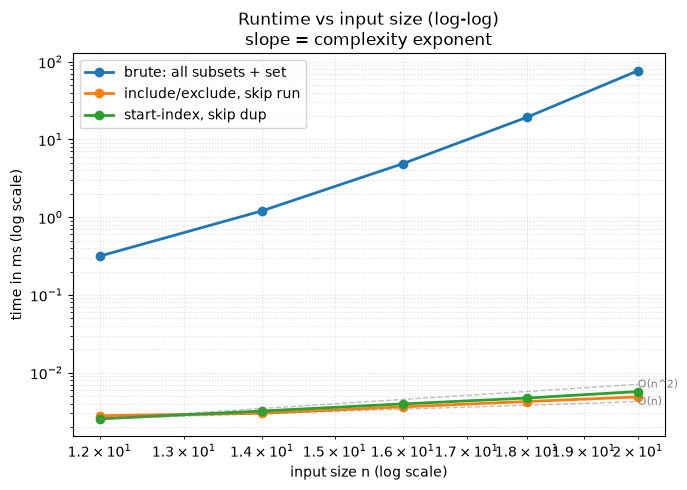

In [6]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

def make_worst_case(n):
    return ([1] * n, n // 2)          # n equal values, exactly one answer
solutions = {
    "brute: all subsets + set": combination_sum2_brute,
    "include/exclude, skip run": combination_sum2_include_exclude,
    "start-index, skip dup": combination_sum2_start_index,
}
sizes = [12, 14, 16, 18, 20]          # n, +2 per step

_ = benchmark(solutions, make_worst_case, sizes, repeats=3, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Combinations](README.md) — the start-index template with `i + 1` (no reuse) plus the sorted sibling-skip `if i > start and c[i] == c[i - 1]: continue`.
- **Dedupe while generating, not after:** a set of tuples gives the right answer but still pays for every duplicate branch; the sibling-skip never creates them.
- **`i > start`, not `i > 0`:** the skip applies only between siblings at one level; the first copy at each level is always tried, so `[1, 1, 6]` survives.
- **Sort does double duty:** `break` on overshoot, and duplicates become neighbours.
- **Signal:** "may contain duplicates" + "each number used once" + "no duplicate combinations".
- **Related problems:** Combination Sum (reuse → recurse with `i`), Subsets II (same sibling-skip, record every node), Permutations II (skip with a `used` array), 3Sum (sort + skip duplicates with pointers).
- **Common pitfalls:**
  1. Skipping with `i > 0` instead of `i > start`: loses answers like `[1, 1, 6]`.
  2. Forgetting to sort first: duplicates aren't adjacent, so the skip misses them.
  3. Recursing with `i` (Combination Sum habit): reuses an element.
  4. Using `res.append(path)` without a copy, or forgetting `path.pop()`.